In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, 
    roc_curve, ConfusionMatrixDisplay
)
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
column_names = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'
]

if os.path.exists('heart.csv'):
    df = pd.read_csv('heart.csv')
    print("Loaded local heart.csv successfully.")
else:
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
    df = pd.read_csv(url, names=column_names, na_values='?')
    # Convert multi-class severity (1-4) into binary target (0 = No Disease, 1 = Disease)
    df['target'] = (df['target'] > 0).astype(int)
    df.to_csv('heart.csv', index=False)
    print("Downloaded UCI Heart Disease dataset and saved as heart.csv.")

print(f"Dataset Shape: {df.shape}")
df.head()

Downloaded UCI Heart Disease dataset and saved as heart.csv.
Dataset Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Missing Values per Column:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Target Class Distribution:
 target
0    0.541
1    0.459
Name: proportion, dtype: float64


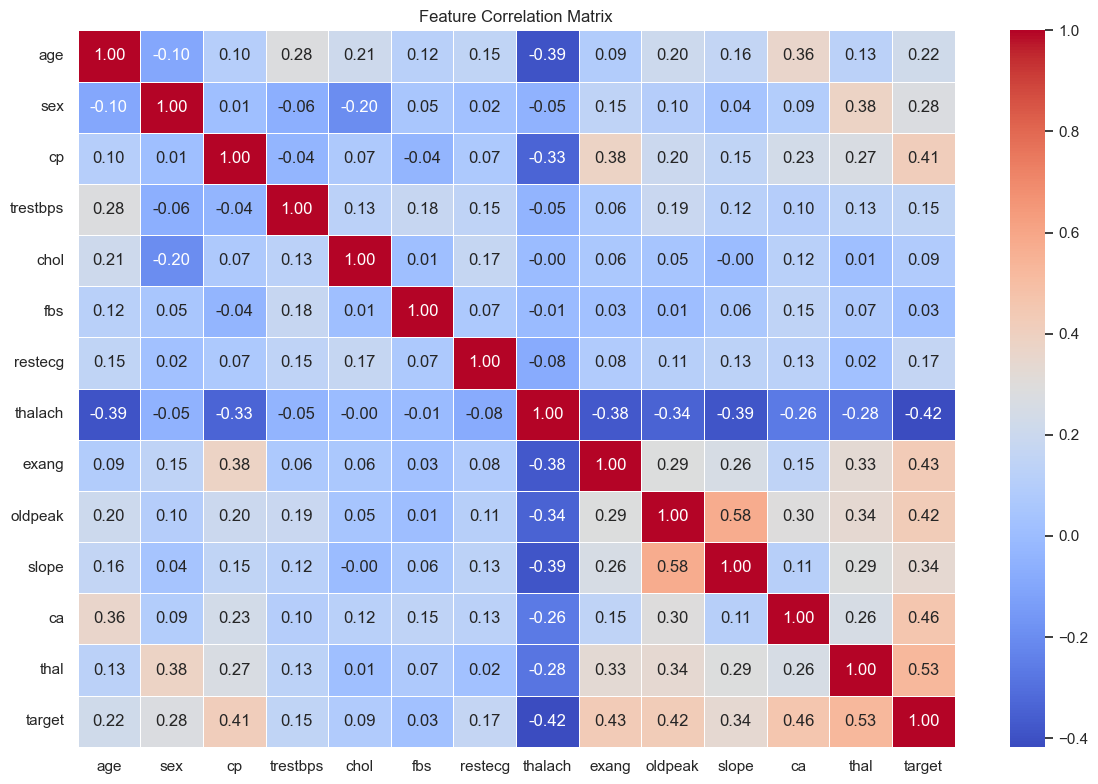

In [3]:
# Ensure target is strictly binary (0 or 1)
df['target'] = (df['target'] > 0).astype(int)

print("Missing Values per Column:\n", df.isnull().sum())
print("\nTarget Class Distribution:\n", df['target'].value_counts(normalize=True).round(3))

# Plot Correlation Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [4]:
X = df.drop('target', axis=1)
y = df['target']

# Define feature groups
numeric_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
categorical_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

# Stratified split maintains the exact ratio of positive/negative cases
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Numerical pipeline: Impute missing values with median, then standardize
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical pipeline: Impute missing values with mode, then One-Hot Encode
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine into a single preprocessor
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print(f"Training samples: {X_train.shape[0]} | Testing samples: {X_test.shape[0]}")

Training samples: 242 | Testing samples: 61


In [5]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    clf_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
    scores = cross_validate(
        clf_pipeline, X_train, y_train, cv=cv,
        scoring=['accuracy', 'recall', 'roc_auc']
    )
    results.append({
        "Model": name,
        "CV Accuracy": scores['test_accuracy'].mean().round(4),
        "CV Recall": scores['test_recall'].mean().round(4),
        "CV ROC-AUC": scores['test_roc_auc'].mean().round(4)
    })

results_df = pd.DataFrame(results).sort_values(by="CV ROC-AUC", ascending=False)
display(results_df)

,Model,CV Accuracy,CV Recall,CV ROC-AUC
0,Logistic Regression,0.8471,0.7834,0.9025
1,Random Forest,0.8181,0.7826,0.8972
2,XGBoost,0.7895,0.7747,0.8597


Best Hyperparameters: {'classifier__class_weight': None, 'classifier__max_depth': 8, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}

Test Set Classification Report:

              precision    recall  f1-score   support

           0       0.97      0.85      0.90        33
           1       0.84      0.96      0.90        28

    accuracy                           0.90        61
   macro avg       0.90      0.91      0.90        61
weighted avg       0.91      0.90      0.90        61

Test ROC-AUC Score: 0.9535


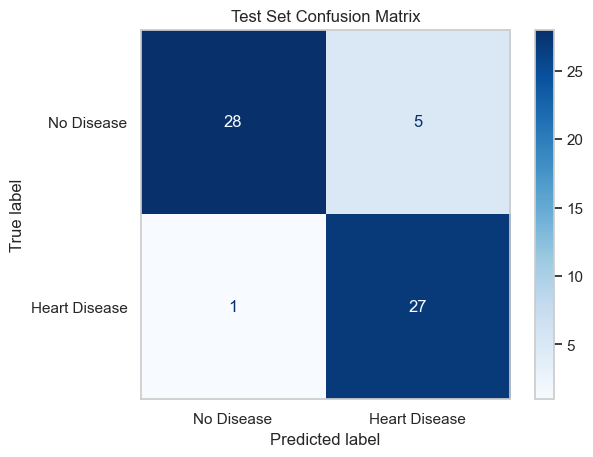

In [6]:
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [4, 6, 8, None],
    'classifier__min_samples_split': [2, 5],
    'classifier__class_weight': [None, 'balanced']
}

grid_search = GridSearchCV(
    rf_pipeline, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1
)
grid_search.fit(X_train, y_train)

best_pipeline = grid_search.best_estimator_
print("Best Hyperparameters:", grid_search.best_params_)

# Evaluate on Test Set
y_pred = best_pipeline.predict(X_test)
y_prob = best_pipeline.predict_proba(X_test)[:, 1]

print("\nTest Set Classification Report:\n")
print(classification_report(y_test, y_pred))
print(f"Test ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

# Plot Confusion Matrix
ConfusionMatrixDisplay.from_estimator(
    best_pipeline, X_test, y_test, display_labels=["No Disease", "Heart Disease"], cmap="Blues"
)
plt.grid(False)
plt.title("Test Set Confusion Matrix")
plt.show()

In [7]:
model_filename = 'heart_disease_pipeline.pkl'
joblib.dump(best_pipeline, model_filename)
print(f"Full preprocessing and model pipeline saved as {model_filename}")

Full preprocessing and model pipeline saved as heart_disease_pipeline.pkl


In [8]:
loaded_model = joblib.load('heart_disease_pipeline.pkl')
sample_patient = X_test.iloc[[0]]
pred_class = loaded_model.predict(sample_patient)[0]
pred_prob = loaded_model.predict_proba(sample_patient)[0][1]

print(f"Predicted Class: {pred_class} | Actual Class: {y_test.iloc[0]} | Risk Probability: {pred_prob:.1%}")

Predicted Class: 0 | Actual Class: 0 | Risk Probability: 23.8%
